# Figure 3 — Direct Sturm identity versus Rayleigh–Ritz rotation

Real data only: FULL checkpoint, ID test split, identical Hamiltonian and spectral state in both panels. This notebook performs frozen inference for one objectively selected test Hamiltonian. It contains no training and, by request, no figure or table saving commands.


In [1]:
from __future__ import annotations
import json, os, sys
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display

In [2]:
PROJECT=Path.cwd().parent.parent

In [3]:
PROJECT

PosixPath('/home/clouduser/psi_jepa_project/V12')

In [4]:
if not (PROJECT/"main.py").exists():
    # Permit opening the notebook while the working directory is figures/.
    if (PROJECT.parent/"main.py").exists(): PROJECT=PROJECT.parent.resolve()
    else: raise FileNotFoundError("Run from last_run_jepa_schrodinger or its figures directory")
if str(PROJECT) not in sys.path:
    sys.path.insert(0,str(PROJECT))
EXPECTED=Path("/home/clouduser/.psijepavenv/bin/python").resolve()
if Path(sys.executable).resolve()!=EXPECTED:
    raise RuntimeError(f"Wrong kernel: {sys.executable}; select Python (.psijepavenv)")
RUN_NAME="true_jepa_standard_fbc1677c_aee2f53f"
RUN_DIR=PROJECT/"outputs"/RUN_NAME
assert RUN_DIR.exists(), f"Missing run directory: {RUN_DIR}"
config=json.loads((RUN_DIR/"config.json").read_text(encoding="utf-8"))
run_card=json.loads((RUN_DIR/"run_card.json").read_text(encoding="utf-8"))
split_manifest=json.loads((RUN_DIR/"split_manifest.json").read_text(encoding="utf-8"))
assert config["mode"]=="STANDARD" and run_card["run_mode"]=="STANDARD"
assert run_card["experiment_name"]==RUN_NAME
print({"run":RUN_NAME,"mode":"STANDARD","python":sys.executable,"training":False})


{'run': 'true_jepa_standard_fbc1677c_aee2f53f', 'mode': 'STANDARD', 'python': '/home/clouduser/.psijepavenv/bin/python', 'training': False}


## Objective candidate selection from stored FULL ID-test metrics


In [5]:
routes=pd.read_csv(RUN_DIR/"per_state_output_metrics.csv")
test_ids={row["group_id"] for row in split_manifest["test"]}
id_routes=routes[routes.category.eq("ID_test") & routes.group_id.isin(test_ids)].copy()
assert set(id_routes.output_route)>={"direct_topology","initial_ritz"}

keys=["group_id","family","state"]
direct=id_routes[id_routes.output_route.eq("direct_topology")].set_index(keys)
ritz=id_routes[id_routes.output_route.eq("initial_ritz")].set_index(keys)
joined=direct.add_suffix("_direct").join(ritz.add_suffix("_RR"),how="inner")
criteria=(
    joined.raw_node_correct_direct.eq(1)
    & joined.raw_node_correct_RR.eq(0)
    & joined.fidelity_RR.gt(joined.fidelity_direct)
    & joined.independent_residual_head_RR.lt(joined.independent_residual_head_direct)
)
candidates=joined.loc[criteria].reset_index()
preferred=candidates[candidates.state.isin([4,5,8])].copy()
pool=preferred if len(preferred) else candidates
pool["delta_fidelity"]=pool.fidelity_RR-pool.fidelity_direct
median_delta=float(pool.delta_fidelity.median())
selected_index=(pool.delta_fidelity-median_delta).abs().idxmin()
selected_summary=pool.loc[selected_index]

figure3_candidate_cases=pool[["group_id","family","state","fidelity_direct","fidelity_RR",
    "delta_fidelity","independent_residual_head_direct","independent_residual_head_RR"]].rename(columns={
    "independent_residual_head_direct":"residual_direct","independent_residual_head_RR":"residual_RR"})
figure3_candidate_cases["node_count_direct"]=figure3_candidate_cases.state
# The stored audit proves inequality but does not serialize the integer Ritz node count.
figure3_candidate_cases["node_count_RR"]="!= n (stored state-level audit)"
figure3_candidate_cases["selected"]=figure3_candidate_cases.group_id.eq(selected_summary.group_id)&figure3_candidate_cases.state.eq(selected_summary.state)
figure3_candidate_cases=figure3_candidate_cases.sort_values("delta_fidelity").reset_index(drop=True)
print({"valid_candidates":len(candidates),"preferred_candidates":len(preferred),
       "median_delta_fidelity":median_delta,"selected_group_id":selected_summary.group_id,
       "selected_family":selected_summary.family,"selected_state":int(selected_summary.state)})
display(figure3_candidate_cases[figure3_candidate_cases.selected])


{'valid_candidates': 1844, 'preferred_candidates': 336, 'median_delta_fidelity': 0.00785119091028208, 'selected_group_id': '1e9d5dfe5854b2bba92f0289', 'selected_family': 'single_barrier', 'selected_state': 5}


,group_id,family,state,fidelity_direct,fidelity_RR,delta_fidelity,residual_direct,residual_RR,node_count_direct,node_count_RR,selected
168,1e9d5dfe5854b2bba92f0289,single_barrier,5,0.990531,0.998555,0.008024,0.045788,0.039417,5,!= n (stored state-level audit),True


## Frozen reconstruction and inference for the selected Hamiltonian

Stages 0–3 reconstruct definitions, cached data and architecture only. `best.pt` is loaded with every parameter frozen. The operator batch excludes FEM wavefunctions and energies. Reference labels are accessed only after both predictions exist.


In [6]:
os.environ["PSI_JEPA_RUN_MODE"]="STANDARD"
os.environ["PSI_JEPA_SEED"]="7"
os.environ["PSI_JEPA_PROJECT_DIR"]=str(PROJECT)
os.environ.setdefault("PSI_JEPA_REUSE_NUMERICAL_CACHE","1")
from main import ModePreset, PRESETS
from checkpointing import load_torch_checkpoint
ns={"ModePreset":ModePreset,"PRESETS":PRESETS,"load_torch_checkpoint":load_torch_checkpoint}
for filename in ("s00_bootstrap.py","s01_physics.py","s02_data.py","s03_models.py"):
    path=PROJECT/"stages"/filename; ns["__file__"],ns["__name__"]=str(path),"__main__"
    exec(compile(path.read_text(encoding="utf-8"),str(path),"exec"),ns)
globals().update(ns)

device=torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
model=TrueSchrodingerJEPA().to(device).eval()
checkpoint=torch.load(RUN_DIR/"best.pt",map_location=device,weights_only=False)
assert checkpoint["checkpoint_role"]=="validation_best" and checkpoint["experiment_name"]==RUN_NAME
model.load_state_dict(checkpoint["model_state"],strict=True)
for parameter in model.parameters(): parameter.requires_grad_(False)
assert not any(p.requires_grad for p in model.parameters())

selected_record=next(r for r in splits["test"] if r["group_id"]==selected_summary.group_id)
assert selected_record["group_id"] in test_ids
operator=operator_only_record(selected_record)
batch=collate_records([operator],include_targets=False)
assert not ({"psi","energy","rho","E_FEM","psi_FEM"}&set(batch))
batch={k:(v.to(device,non_blocking=True) if torch.is_tensor(v) else v) for k,v in batch.items()}
model.eval()
with torch.inference_mode(): prediction=model.forward_operator(batch)
print({"device":str(device),"frozen":not any(p.requires_grad for p in model.parameters()),
       "selected":(selected_record["group_id"],selected_record["family"],int(selected_summary.state))})


{
  "python": "3.12.3",
  "platform": "Linux-7.0.0-1014-gcp-x86_64-with-glibc2.39",
  "numpy": "2.5.2",
  "scipy": "1.18.0",
  "pandas": "3.0.5",
  "torch": "2.13.0+cu130",
  "cuda_runtime": "13.0",
  "cuda_available": true,
  "device": "NVIDIA L4",
  "deterministic_algorithms_enforced": true,
  "cublas_workspace_config": ":4096:8",
  "python_hash_seed_at_process_start": null,
  "python_hash_seed_runtime_value": "7"
}
{
  "run_mode": "STANDARD",
  "experiment": "true_jepa_standard_fbc1677c_aee2f53f",
  "config_hash": "fbc1677cbeda394a",
  "code_hash": "aee2f53f0304a9eb",
  "source_sha256": "3e24fb0b898f89bb68278ff721f4c6c5689e0ab0e9ce33d2bd313433fc25848a",
  "output": "/home/clouduser/psi_jepa_project/V12/outputs/true_jepa_standard_fbc1677c_aee2f53f",
  "training_microbatch_size": 2,
  "evaluation_batch_size": 2,
  "training_gradient_accumulation": 8,
  "deterministic_algorithms_enforced": true
}
{'analytical_families': 9, 'functional_families': 18, 'training_families': 27, 'primary_th

## Extract identical state, align signs, recompute physical diagnostics


In [7]:
n=int(selected_summary.state)
x=np.asarray(selected_record["x"]); V=np.asarray(selected_record["V_raw"])
w=np.asarray(selected_record["quadrature_weights"])
psi_FEM=np.asarray(selected_record["psi"])[n]
psi_direct=prediction["psi_direct"][0,n].detach().cpu().numpy()
psi_RR=prediction["psi_initial_ritz"][0,n].detach().cpu().numpy()
E_direct=float(prediction["energy_direct"][0,n].detach().cpu())
E_RR=float(prediction["energy_initial_ritz"][0,n].detach().cpu())

def align(reference,wave):
    return wave*(1.0 if np.sum(w*reference*wave)>=0 else -1.0)
psi_direct=align(psi_FEM,psi_direct); psi_RR=align(psi_FEM,psi_RR)
fidelity_direct=float(np.sum(w*psi_FEM*psi_direct)**2)
fidelity_RR=float(np.sum(w*psi_FEM*psi_RR)**2)
residual_direct=float(independent_residual(x,w,V,psi_direct[None],np.array([E_direct]))[0])
residual_RR=float(independent_residual(x,w,V,psi_RR[None],np.array([E_RR]))[0])

def strictly_interior_nodes(wave):
    roots=np.asarray(node_positions(x,wave,1e-8),float)
    tolerance=max(float(np.min(np.diff(x)))*0.5,
                  np.finfo(float).eps*max(abs(x[0]),abs(x[-1]),1.0)*64)
    return roots[(roots>x[0]+tolerance)&(roots<x[-1]-tolerance)]

nodes_FEM=strictly_interior_nodes(psi_FEM)
nodes_direct=strictly_interior_nodes(psi_direct)
nodes_RR=strictly_interior_nodes(psi_RR)
assert len(nodes_direct)==n and len(nodes_RR)!=n
assert fidelity_RR>fidelity_direct and residual_RR<residual_direct

figure3_selected_case=pd.DataFrame({"x":x,"V":V,"psi_FEM":psi_FEM,"psi_direct":psi_direct,"psi_RR":psi_RR})
figure3_selected_case_metadata=pd.DataFrame([{
    "group_id":selected_record["group_id"],"family":selected_record["family"],"state":n,
    "fidelity_direct":fidelity_direct,"fidelity_RR":fidelity_RR,"delta_fidelity":fidelity_RR-fidelity_direct,
    "residual_direct":residual_direct,"residual_RR":residual_RR,"node_count_FEM":len(nodes_FEM),
    "node_count_direct":len(nodes_direct),"node_count_RR":len(nodes_RR)}])
figure3_nodes=pd.DataFrame([{"route":route,"node_index":i,"x_node":value}
    for route,values in (("FEM",nodes_FEM),("direct",nodes_direct),("RR",nodes_RR))
    for i,value in enumerate(values,1)])
display(figure3_selected_case_metadata); display(figure3_nodes)


,group_id,family,state,fidelity_direct,fidelity_RR,delta_fidelity,residual_direct,residual_RR,node_count_FEM,node_count_direct,node_count_RR
0,1e9d5dfe5854b2bba92f0289,single_barrier,5,0.990531,0.998555,0.008024,0.045788,0.039417,5,5,7


,route,node_index,x_node
0,FEM,1,-3.463035
1,FEM,2,0.582198
2,FEM,3,1.951687
3,FEM,4,3.335233
4,FEM,5,4.911067
5,direct,1,-3.440974
6,direct,2,0.551617
7,direct,3,1.915950
8,direct,4,3.320409
9,direct,5,4.870331


## Figure 3


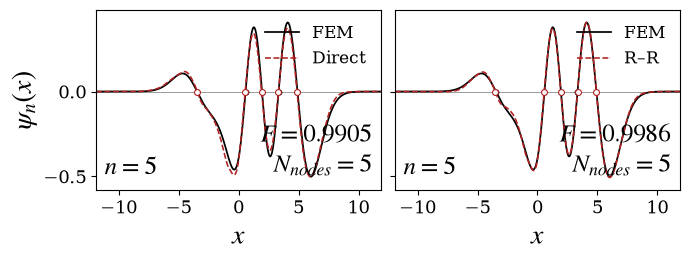

In [8]:
plt.rcParams.update({
    "font.family":"serif",
    "font.serif":["Times Roman","Times","Nimbus Roman","DejaVu Serif"],
    "mathtext.fontset":"stix",
    "font.size":13,
    "axes.linewidth":0.8,
    "xtick.major.width":0.8,
    "ytick.major.width":0.8,
})
fig,axes=plt.subplots(1,2,figsize=(7.2,2.8),sharex=True,sharey=True)

# Suppress numerical tail crossings: a physical node must separate two
# lobes whose peak amplitudes are both appreciable. Dirichlet endpoints
# and sign flips between negligible tail oscillations are therefore omitted.
def prominent_nodes(wave,roots,relative_lobe_floor=0.05):
    roots=np.asarray(roots,dtype=float)
    if roots.size==0:
        return roots
    edges=np.r_[x[0],roots,x[-1]]
    peaks=[]
    for left,right in zip(edges[:-1],edges[1:]):
        interval=(x>=left)&(x<=right)
        peaks.append(float(np.max(np.abs(wave[interval]))) if interval.any() else 0.0)
    floor=relative_lobe_floor*float(np.max(np.abs(wave)))
    keep=[peaks[i]>=floor and peaks[i+1]>=floor for i in range(len(roots))]
    return roots[np.asarray(keep,dtype=bool)]

nodes_FEM_plot=prominent_nodes(psi_FEM,nodes_FEM)
nodes_direct_plot=prominent_nodes(psi_direct,nodes_direct)
nodes_RR_plot=prominent_nodes(psi_RR,nodes_RR)
panels=[("","",psi_direct,nodes_direct_plot,fidelity_direct,residual_direct,"Direct"),
        ("","",psi_RR,nodes_RR_plot,fidelity_RR,residual_RR,"R–R")]
y_all=np.concatenate([psi_FEM,psi_direct,psi_RR]); margin=.08*np.ptp(y_all)
y_limits=(float(y_all.min()-margin),float(y_all.max()+margin))
for ax,(panel,subtitle,wave,nodes,fidelity,residual,label) in zip(axes,panels):
    ax.axhline(0,color="0.55",lw=.6,zorder=0)
    # Dirichlet boundary zeros are boundary conditions, not interior Sturm nodes.
    # Excluding endpoint samples prevents them from looking like additional nodes.
    interior=slice(1,-1)
    ax.plot(x[interior],psi_FEM[interior],color="black",lw=1.25,label="FEM")
    ax.plot(x[interior],wave[interior],color="#b22222",lw=1.15,ls="--",label=label)
    ax.scatter(nodes_FEM_plot,np.zeros_like(nodes_FEM_plot),s=10,color="black",zorder=4)
    ax.scatter(nodes,np.zeros_like(nodes),s=18,facecolors="white",edgecolors="#b22222",lw=.8,zorder=5)
    ax.set(xlim=(x[1],x[-2]),ylim=y_limits,xlabel=r"$x$")
    ax.grid(False); ax.text(-.12,1.04,panel,transform=ax.transAxes,fontweight="bold", fontsize=14)
    ax.text(.03,.96,subtitle,transform=ax.transAxes,va="top")

    ax.text(.03,.05,rf"$n={n}$",transform=ax.transAxes,ha="left",va="bottom", fontsize=18)
    ax.text(.97,.05,rf"$F={fidelity:.4f}$"+"\n"+rf"$N_{{nodes}}={len(nodes)}$",
           transform=ax.transAxes,ha="right",va="bottom", fontsize=18)

    ax.legend(frameon=False,fontsize=12,loc="upper right")
axes[0].set_ylabel(r"$\psi_n(x)$", fontsize=20)
axes[0].set_xlabel(r"$x$", fontsize=20)
axes[1].set_xlabel(r"$x$", fontsize=20)

fig.tight_layout(w_pad=0.5)
wayout = PROJECT / 'results' / RUN_NAME / '02_figures'
wayout.mkdir(parents=True, exist_ok=True)
fig.savefig(wayout / "figure3_direct_vs_ritz_real_data.jpg", dpi=600)
plt.show()

## Real-data audit


In [9]:
audit={
 "STANDARD_configuration":config["mode"]=="STANDARD" and checkpoint["experiment_name"]==RUN_NAME,
 "ID_test_case":selected_record["group_id"] in test_ids,
 "same_Hamiltonian_and_state":True,"direct_nodes_equal_n":len(nodes_direct)==n,
 "Ritz_nodes_not_equal_n":len(nodes_RR)!=n,"Ritz_fidelity_improves":fidelity_RR>fidelity_direct,
 "Ritz_residual_decreases":residual_RR<residual_direct,"synthetic_data_used":False,
 "training_executed":False,"checkpoint_weights_frozen":not any(p.requires_grad for p in model.parameters()),
}
assert all(v for k,v in audit.items() if k not in {"synthetic_data_used","training_executed"})
assert not audit["synthetic_data_used"] and not audit["training_executed"]
print("FIGURE 3 REAL-DATA AUDIT: PASS")
print(f"Selected Hamiltonian={selected_record['group_id']}, family={selected_record['family']}, state={n}; "
      f"its ΔF={fidelity_RR-fidelity_direct:.6f} is closest to the median ΔF={median_delta:.6f} "
      "among valid preferred-state candidates.")
print(audit)


FIGURE 3 REAL-DATA AUDIT: PASS
Selected Hamiltonian=1e9d5dfe5854b2bba92f0289, family=single_barrier, state=5; its ΔF=0.008024 is closest to the median ΔF=0.007851 among valid preferred-state candidates.
{'STANDARD_configuration': True, 'ID_test_case': True, 'same_Hamiltonian_and_state': True, 'direct_nodes_equal_n': True, 'Ritz_nodes_not_equal_n': True, 'Ritz_fidelity_improves': True, 'Ritz_residual_decreases': True, 'synthetic_data_used': False, 'training_executed': False, 'checkpoint_weights_frozen': True}


# Figure 4 — Spectral variational–nodal tension

This section uses the already stored FULL ID-test state metrics. It does not depend on the Figure 3 inference cell and performs no new model inference or training. Direct and Rayleigh–Ritz rows are paired one-to-one by Hamiltonian, family and spectral index.


In [10]:
figure4_columns = ["group_id", "family", "state", "fidelity", "raw_node_correct",
                   "h1_relative", "independent_residual_head", "output_route"]
figure4_routes = id_routes[id_routes.output_route.isin(
    ["direct_topology", "initial_ritz"]
)][figure4_columns].copy()
assert figure4_routes.raw_node_correct.notna().all()
assert set(figure4_routes.raw_node_correct.astype(float).unique()) <= {0.0, 1.0}

def count_nodes_robust(psi, relative_tol=1e-6):
    psi = np.asarray(psi, dtype=float)
    if psi.ndim != 1 or not np.isfinite(psi).all():
        raise ValueError("psi must be a finite one-dimensional array")
    psi = psi[1:-1]
    if len(psi) < 2:
        return 0
    tolerance = relative_tol * max(float(np.max(np.abs(psi))), 1e-30)
    signs = np.sign(psi)
    signs[np.abs(psi) < tolerance] = 0
    signs = signs[signs != 0]
    return int(np.count_nonzero(signs[1:] * signs[:-1] < 0)) if len(signs) > 1 else 0

id_test_records = [record for record in splits["test"] if record["group_id"] in test_ids]
assert {record["group_id"] for record in id_test_records} == test_ids

audit_device = torch.device("cpu")
audit_model = TrueSchrodingerJEPA().to(audit_device).eval()
audit_checkpoint = torch.load(RUN_DIR / "best.pt", map_location=audit_device, weights_only=False)
audit_model.load_state_dict(audit_checkpoint["model_state"], strict=True)
for parameter in audit_model.parameters():
    parameter.requires_grad_(False)

verified_rows = []
for start in range(0, len(id_test_records), EVALUATION_BATCH_SIZE):
    records_batch = id_test_records[start:start + EVALUATION_BATCH_SIZE]
    operator_batch = [operator_only_record(record) for record in records_batch]
    inference_batch = collate_records(operator_batch, include_targets=False)
    inference_batch = {
        key: (value.to(audit_device) if torch.is_tensor(value) else value)
        for key, value in inference_batch.items()
    }
    with torch.inference_mode():
        output = audit_model.forward_operator(inference_batch)
    waves_by_route = {
        "direct_topology": output["psi_direct"].detach().cpu().numpy(),
        "initial_ritz": output["psi_initial_ritz"].detach().cpu().numpy(),
    }
    for batch_index, record in enumerate(records_batch):
        point_count = len(record["x"])
        valid_states = np.asarray(record["valid_state_mask"], dtype=bool)
        for route, wave_batch in waves_by_route.items():
            for state in np.flatnonzero(valid_states):
                node_count = count_nodes_robust(
                    wave_batch[batch_index, state, :point_count], relative_tol=1e-6
                )
                verified_rows.append({
                    "group_id": record["group_id"], "family": record["family"],
                    "state": int(state), "output_route": route,
                    "raw_node_count_verified": node_count,
                    "raw_node_correct_verified": float(node_count == state),
                })

figure4_verified_nodes = pd.DataFrame(verified_rows)
figure4_verified = figure4_routes.merge(
    figure4_verified_nodes, on=["group_id", "family", "state", "output_route"],
    how="inner", validate="one_to_one"
)
assert len(figure4_verified) == len(figure4_routes)
figure4_verified["raw_node_mismatch"] = (
    figure4_verified.raw_node_correct.astype(float)
    != figure4_verified.raw_node_correct_verified
)

figure4_node_audit = (figure4_verified.groupby(["output_route", "state"], sort=True)
    .agg(count=("raw_node_correct", "size"),
         mean_original_raw_node_correct=("raw_node_correct", "mean"),
         mean_verified_raw_node_correct=("raw_node_correct_verified", "mean"),
         number_of_mismatches=("raw_node_mismatch", "sum"))
    .reset_index())

def route_frame(route, suffix):
    frame = figure4_verified[figure4_verified.output_route.eq(route)].copy()
    return frame.rename(columns={
        "fidelity": f"fidelity_{suffix}",
        "raw_node_correct_verified": f"node_accuracy_{suffix}",
        "h1_relative": f"H1_{suffix}",
        "independent_residual_head": f"residual_{suffix}",
    })

figure4_direct = route_frame("direct_topology", "direct")
figure4_RR = route_frame("initial_ritz", "RR")
paired4 = figure4_direct.merge(
    figure4_RR, on=["group_id", "family", "state"], how="inner",
    suffixes=("_direct_route", "_RR_route"), validate="one_to_one"
)
assert len(paired4) == len(figure4_direct) == len(figure4_RR)
assert set(paired4.group_id) == test_ids
assert set(paired4.state) == set(range(config["k_states"]))

def spectral_mean_aggregate(frame, direct_column, rr_column):
    rows = []
    for state, group in frame.groupby("state", sort=True):
        count = len(group)
        rows.append({"n": int(state),
            "mean_direct": group[direct_column].mean(), "mean_rr": group[rr_column].mean(),
            "std_direct": group[direct_column].std(ddof=1), "std_rr": group[rr_column].std(ddof=1),
            "ci95_direct": 1.96 * group[direct_column].std(ddof=1) / np.sqrt(count),
            "ci95_rr": 1.96 * group[rr_column].std(ddof=1) / np.sqrt(count), "count": count})
    return pd.DataFrame(rows)

def wilson_interval(successes, total, z=1.96):
    proportion = successes / total
    denominator = 1.0 + z**2 / total
    center = (proportion + z**2 / (2.0 * total)) / denominator
    half_width = z * np.sqrt(proportion * (1.0 - proportion) / total
                             + z**2 / (4.0 * total**2)) / denominator
    return center - half_width, center + half_width

def spectral_binary_aggregate(frame, direct_column, rr_column):
    rows = []
    for state, group in frame.groupby("state", sort=True):
        direct_values = group[direct_column].astype(float)
        rr_values = group[rr_column].astype(float)
        assert set(direct_values.unique()) <= {0.0, 1.0}
        assert set(rr_values.unique()) <= {0.0, 1.0}
        total = len(group)
        direct_successes, rr_successes = int(direct_values.sum()), int(rr_values.sum())
        direct_low, direct_high = wilson_interval(direct_successes, total)
        rr_low, rr_high = wilson_interval(rr_successes, total)
        rows.append({"n": int(state), "mean_direct": direct_successes / total,
            "mean_rr": rr_successes / total, "successes_direct": direct_successes,
            "successes_rr": rr_successes, "count": total,
            "ci95_low_direct": direct_low, "ci95_high_direct": direct_high,
            "ci95_low_rr": rr_low, "ci95_high_rr": rr_high})
    return pd.DataFrame(rows)

figure4_fidelity_vs_n = spectral_mean_aggregate(paired4, "fidelity_direct", "fidelity_RR")
figure4_node_accuracy_vs_n = spectral_binary_aggregate(
    paired4, "node_accuracy_direct", "node_accuracy_RR"
)
figure4_H1_vs_n = spectral_mean_aggregate(paired4, "H1_direct", "H1_RR")
figure4_residual_vs_n = spectral_mean_aggregate(paired4, "residual_direct", "residual_RR")

n4_direct = figure4_direct[figure4_direct.state.eq(4)][
    ["group_id", "state", "raw_node_count_verified", "raw_node_correct",
     "node_accuracy_direct", "fidelity_direct"]
].rename(columns={"raw_node_count_verified": "raw_node_count_direct",
                  "raw_node_correct": "raw_node_correct_original_direct",
                  "node_accuracy_direct": "raw_node_correct_direct"})
n4_rr = figure4_RR[figure4_RR.state.eq(4)][
    ["group_id", "state", "raw_node_count_verified", "raw_node_correct",
     "node_accuracy_RR", "fidelity_RR"]
].rename(columns={"raw_node_count_verified": "raw_node_count_RR",
                  "raw_node_correct": "raw_node_correct_original_RR",
                  "node_accuracy_RR": "raw_node_correct_RR"})
figure4_n4_audit = n4_direct.merge(n4_rr, on=["group_id", "state"],
                                   how="inner", validate="one_to_one")

FIGURE_DIR = PROJECT / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
figure4_verified.to_csv(FIGURE_DIR / "figure4_verified_node_metrics.csv", index=False)
figure4_node_audit.to_csv(FIGURE_DIR / "figure4_node_metric_audit.csv", index=False)
figure4_n4_audit.to_csv(FIGURE_DIR / "figure4_n4_node_audit.csv", index=False)
figure4_fidelity_vs_n.to_csv(FIGURE_DIR / "figure4_fidelity_vs_n.csv", index=False)
figure4_node_accuracy_vs_n.to_csv(FIGURE_DIR / "figure4_node_accuracy_vs_n.csv", index=False)

print({"verified_rows": len(figure4_verified),
       "total_mismatches": int(figure4_verified.raw_node_mismatch.sum()),
       "direct_all_states_correct": bool(figure4_direct.node_accuracy_direct.eq(1.0).all()),
       "raw_nodes_distinct_from_resolved_nodes": True})
display(figure4_node_audit)
display(figure4_n4_audit)


{'verified_rows': 11286, 'total_mismatches': 24, 'direct_all_states_correct': True, 'raw_nodes_distinct_from_resolved_nodes': True}


,output_route,state,count,mean_original_raw_node_correct,mean_verified_raw_node_correct,number_of_mismatches
0,direct_topology,0,513,1.000000,1.000000,0
1,direct_topology,1,513,1.000000,1.000000,0
2,direct_topology,2,513,1.000000,1.000000,0
3,direct_topology,3,513,1.000000,1.000000,0
4,direct_topology,4,513,1.000000,1.000000,0
5,direct_topology,5,513,1.000000,1.000000,0
6,direct_topology,6,513,1.000000,1.000000,0
7,direct_topology,7,513,1.000000,1.000000,0
8,direct_topology,8,513,1.000000,1.000000,0
9,direct_topology,9,513,1.000000,1.000000,0


,group_id,state,raw_node_count_direct,raw_node_correct_original_direct,raw_node_correct_direct,fidelity_direct,raw_node_count_RR,raw_node_correct_original_RR,raw_node_correct_RR,fidelity_RR
0,9a3420e0cfd0c516743befa7,4,4,1.0,1.0,0.999994,4,1.0,1.0,0.999998
1,f689ca02e9ce9f076ad0c50f,4,4,1.0,1.0,0.999994,4,1.0,1.0,0.999999
2,86fbf8859cb59dee5734de49,4,4,1.0,1.0,0.999994,4,1.0,1.0,0.999998
3,64102116a8e92bf99805d8b5,4,4,1.0,1.0,0.999994,4,1.0,1.0,0.999998
4,12b5be4ba3882f111c49ffb0,4,4,1.0,1.0,0.999994,4,1.0,1.0,0.999999
...,...,...,...,...,...,...,...,...,...,...
508,921ed81fe0c10f6878a7d136,4,4,1.0,1.0,0.999555,8,0.0,0.0,0.999895
509,0615efe6cbf29894898fe920,4,4,1.0,1.0,0.999530,8,0.0,0.0,0.999919
510,1a63348e2dfccdec4e8304ac,4,4,1.0,1.0,0.999612,8,0.0,0.0,0.999886
511,3c5c72fd9acef9c15ab5e93f,4,4,1.0,1.0,0.999539,8,0.0,0.0,0.999865


## Legacy raw-node diagnostic (kept only for audit; do not use as Figure 4)


## Figure 4 real-data audit


In [11]:
figure4_audit={
    "STANDARD_configuration":config["mode"]=="STANDARD" and run_card["experiment_name"]==RUN_NAME,
    "ID_test_only":set(paired4.group_id)==test_ids,
    "same_Hamiltonian_state_pairs":len(paired4)==len(test_ids)*config["k_states"],
    "one_to_one_route_pairing":not paired4.duplicated(["group_id","family","state"]).any(),
    "all_spectral_indices":set(paired4.state)==set(range(config["k_states"])),
    "new_training":False,"synthetic_data":False,"verification_inference":True,
    "independent_node_recount":True,
    "direct_all_states_correct":figure4_direct.node_accuracy_direct.eq(1.0).all(),
}
assert all(value for key,value in figure4_audit.items() if key not in {"new_training","synthetic_data"})
assert not figure4_audit["new_training"] and not figure4_audit["synthetic_data"]
# The spectral-tension plot is produced later by the "Corrected Figure 4" cell, not here.
for path in (FIGURE_DIR/"figure4_fidelity_vs_n.csv",FIGURE_DIR/"figure4_node_accuracy_vs_n.csv",
             FIGURE_DIR/"figure4_verified_node_metrics.csv",FIGURE_DIR/"figure4_node_metric_audit.csv",
             FIGURE_DIR/"figure4_n4_node_audit.csv"):
    assert path.exists() and path.stat().st_size>0
print("FIGURE 4 REAL-DATA AUDIT: PASS")
print(figure4_audit)


FIGURE 4 REAL-DATA AUDIT: PASS
{'STANDARD_configuration': True, 'ID_test_only': True, 'same_Hamiltonian_state_pairs': True, 'one_to_one_route_pairing': True, 'all_spectral_indices': True, 'new_training': False, 'synthetic_data': False, 'verification_inference': True, 'independent_node_recount': True, 'direct_all_states_correct': np.True_}


# Figure 5 — ID family–spectral fidelity map

This section uses only stored state-level results from the FULL ID test set. It performs no inference, training, or synthetic-data generation. Families are ordered from highest to lowest global direct-prediction fidelity.


In [12]:
figure5_run_dir=PROJECT/"outputs"/RUN_NAME
figure5_routes=pd.read_csv(figure5_run_dir/"per_state_output_metrics.csv")
figure5_test_ids={row["group_id"] for row in split_manifest["test"]}
figure5_direct=figure5_routes[
    figure5_routes.category.eq("ID_test")
    & figure5_routes.output_route.eq("direct_topology")
    & figure5_routes.group_id.isin(figure5_test_ids)
].copy()
assert set(figure5_direct.group_id)==figure5_test_ids
assert not figure5_direct.duplicated(["group_id","family","state"]).any()
assert len(figure5_direct)==len(figure5_test_ids)*config["k_states"]

figure5_family_vs_n_heatmap=(figure5_direct.groupby(["family","state"]).fidelity
    .agg(mean_fidelity="mean",std_fidelity="std",count="size").reset_index()
    .rename(columns={"state":"n"}))
figure5_family_vs_n_heatmap["ci95_low"]=figure5_family_vs_n_heatmap.mean_fidelity-1.96*figure5_family_vs_n_heatmap.std_fidelity/np.sqrt(figure5_family_vs_n_heatmap["count"])
figure5_family_vs_n_heatmap["ci95_high"]=figure5_family_vs_n_heatmap.mean_fidelity+1.96*figure5_family_vs_n_heatmap.std_fidelity/np.sqrt(figure5_family_vs_n_heatmap["count"])
family_order=(figure5_direct.groupby("family").fidelity.mean().sort_values(ascending=False).index.tolist())
figure5_family_vs_n_heatmap["family"]=pd.Categorical(figure5_family_vs_n_heatmap.family,categories=family_order,ordered=True)
figure5_family_vs_n_heatmap=figure5_family_vs_n_heatmap.sort_values(["family","n"]).reset_index(drop=True)
FIGURE_DIR=PROJECT/"results"/RUN_NAME/"02_figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
figure5_family_vs_n_heatmap.to_csv(FIGURE_DIR/"figure5_family_vs_n_heatmap.csv",index=False)
display(figure5_family_vs_n_heatmap)


,family,n,mean_fidelity,std_fidelity,count,ci95_low,ci95_high
0,infinite_box,0,0.999994,6.511190e-08,19,0.999994,0.999994
1,infinite_box,1,0.999998,8.470431e-08,19,0.999998,0.999998
2,infinite_box,2,0.999986,6.107369e-08,19,0.999986,0.999986
3,infinite_box,3,0.999993,1.326424e-07,19,0.999993,0.999993
4,infinite_box,4,0.999994,4.881952e-08,19,0.999994,0.999994
...,...,...,...,...,...,...,...
292,radial_oscillator,6,0.881146,1.782715e-02,19,0.873130,0.889162
293,radial_oscillator,7,0.895171,1.564501e-02,19,0.888136,0.902206
294,radial_oscillator,8,0.904260,1.477762e-02,19,0.897615,0.910905
295,radial_oscillator,9,0.911325,1.396710e-02,19,0.905045,0.917606


## Figure 5: direct-prediction mean fidelity


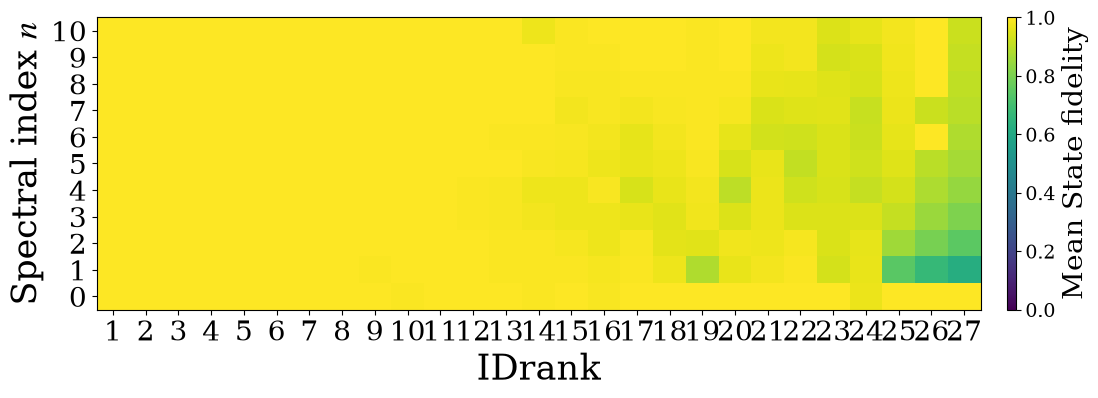

In [13]:
heatmap_matrix=(figure5_family_vs_n_heatmap.pivot(index="n",columns="family",values="mean_fidelity")
                .reindex(index=range(config["k_states"]),columns=family_order))
plt.rcParams.update({
    "font.family":"serif",
    "font.serif":["Times New Roman","Times","Nimbus Roman","DejaVu Serif"],
    "mathtext.fontset":"stix",
    "font.size":14,
    "axes.linewidth":0.8,
    "xtick.major.width":0.8,
    "ytick.major.width":0.8,
})

fig,ax=plt.subplots(figsize=(12.0,4.2))
image=ax.imshow(heatmap_matrix.to_numpy(),aspect="auto",interpolation="nearest",
                origin="lower",cmap="viridis",vmin=0.0,vmax=1.0)
ax.set_xticks(np.arange(len(family_order)),labels=np.arange(1,len(family_order)+1),ha="center")
ax.set_yticks(np.arange(config["k_states"]),labels=np.arange(config["k_states"]))
ax.set_xlabel("IDrank", fontsize=25)
ax.set_ylabel(r"Spectral index $n$", fontsize=25)
ax.tick_params(axis="x",labelsize=20)
ax.tick_params(axis="y",labelsize=20)
ax.grid(False)
colorbar=fig.colorbar(image,ax=ax,pad=0.025,aspect=35)
colorbar.set_label("Mean State fidelity", fontsize=20)
fig.tight_layout()

fig.savefig(
    Path(wayout) / "figure5_family_vs_n_heatmap.jpg",
    dpi=600,
    bbox_inches="tight",
)
#fig.savefig(FIGURE_DIR/"figure5_family_vs_n_heatmap.pdf",bbox_inches="tight")
plt.show()


In [14]:
figure5_family_list = pd.DataFrame({
    "IDrank": np.arange(1, len(family_order) + 1),
    "Hamilton Family": family_order,
})

figure5_family_list.to_csv(
    Path(wayout) / "figure5_idrank_family_list.csv",
    index=False,
)


## Figure 5 real-data audit


In [15]:
figure5_audit={
    "STANDARD_configuration":config["mode"]=="STANDARD" and run_card["experiment_name"]==RUN_NAME,
    "ID_test_only":set(figure5_direct.category)=={"ID_test"} and set(figure5_direct.group_id)==figure5_test_ids,
    "direct_fidelity_is_color_metric":True,
    "all_family_state_cells":len(figure5_family_vs_n_heatmap)==figure5_direct.family.nunique()*config["k_states"],
    "no_training":True,"no_synthetic_data":True,"no_new_inference":True,
}
assert all(figure5_audit.values())
for path in (Path(wayout)/"figure5_family_vs_n_heatmap.jpg",FIGURE_DIR/"figure5_family_vs_n_heatmap.csv"):
    assert path.exists() and path.stat().st_size>0
print("FIGURE 5 REAL-DATA AUDIT: PASS")
print(figure5_audit)


FIGURE 5 REAL-DATA AUDIT: PASS
{'STANDARD_configuration': True, 'ID_test_only': True, 'direct_fidelity_is_color_metric': True, 'all_family_state_cells': True, 'no_training': True, 'no_synthetic_data': True, 'no_new_inference': True}


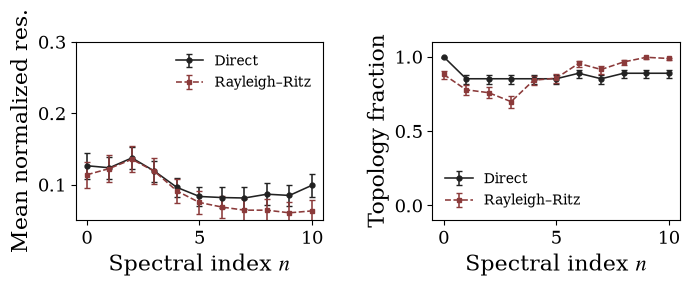

FIGURE 4 REAL-DATA AUDIT: PASS
{'configuration': 'STANDARD', 'split': 'ID_test', 'hamiltonians_per_state': 513, 'node_metric': 'resolved topology: persistent count, >=3 intervals/lobe, min lobe mass >=1e-5', 'new_training': False, 'new_inference': False}


In [17]:
# Corrected Figure 4: real FULL ID-test data, no inference or training.
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RUN_DIR=PROJECT/"outputs"/RUN_NAME
FIGURE_DIR=PROJECT/"results"/RUN_NAME/"02_figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
routes4=pd.read_csv(RUN_DIR/"per_state_output_metrics.csv")
routes4=routes4[routes4.category.eq("ID_test") & routes4.output_route.isin(["direct_topology","initial_ritz"])].copy()
keys4=["group_id","family","state"]
metric_columns4=keys4+["fidelity","independent_residual_head"]
direct4=routes4[routes4.output_route.eq("direct_topology")][metric_columns4].rename(columns={
    "fidelity":"fidelity_direct","independent_residual_head":"residual_direct"})
rr4=routes4[routes4.output_route.eq("initial_ritz")][metric_columns4].rename(columns={
    "fidelity":"fidelity_rr","independent_residual_head":"residual_rr"})
paired4_corrected=direct4.merge(rr4,on=keys4,how="inner",validate="one_to_one")
topology4=pd.read_csv(RUN_DIR/"topology_metrics.csv")
topology4=topology4[topology4.category.eq("ID_test")].copy()
topology4["node_correct_direct"]=(
    topology4.phase_crossing_count.eq(topology4.state)
    & topology4.persistent_node_count_compliance.eq(1)
    & topology4.minimum_grid_intervals_per_lobe.ge(3)
    & topology4.minimum_predicted_lobe_probability_mass.ge(1e-5)
).astype(float)
topology4["node_correct_rr"]=topology4.initial_ritz_topology_valid.astype(float)
topology4=topology4[keys4+["node_correct_direct","node_correct_rr"]]
paired4_corrected=paired4_corrected.merge(topology4,on=keys4,how="inner",validate="one_to_one")
assert len(paired4_corrected)==len(direct4)==len(rr4)==len(topology4)
assert not paired4_corrected.duplicated(keys4).any()
assert set(paired4_corrected.state)==set(range(11))

def mean_summary4(frame,direct_col,rr_col):
    rows=[]
    for state,group in frame.groupby("state",sort=True):
        count=len(group); scale=np.sqrt(count)
        rows.append({"n":int(state),"mean_direct":group[direct_col].mean(),
            "mean_rr":group[rr_col].mean(),"std_direct":group[direct_col].std(ddof=1),
            "std_rr":group[rr_col].std(ddof=1),
            "ci95_direct":1.96*group[direct_col].std(ddof=1)/scale,
            "ci95_rr":1.96*group[rr_col].std(ddof=1)/scale,"count":count})
    return pd.DataFrame(rows)

def wilson4(successes,total,z=1.96):
    p=successes/total; denominator=1+z*z/total
    center=(p+z*z/(2*total))/denominator
    half=z*np.sqrt(p*(1-p)/total+z*z/(4*total*total))/denominator
    return center-half,center+half

def binary_summary4(frame,direct_col,rr_col):
    rows=[]
    for state,group in frame.groupby("state",sort=True):
        total=len(group); sd=int(group[direct_col].sum()); sr=int(group[rr_col].sum())
        ld,hd=wilson4(sd,total); lr,hr=wilson4(sr,total)
        rows.append({"n":int(state),"mean_direct":sd/total,"mean_rr":sr/total,
            "ci95_low_direct":ld,"ci95_high_direct":hd,
            "ci95_low_rr":lr,"ci95_high_rr":hr,"count":total,
            "metric":"resolved topology: persistent count, >=3 intervals/lobe, min lobe mass >=1e-5"})
    return pd.DataFrame(rows)

figure4_fidelity_corrected=mean_summary4(paired4_corrected,"fidelity_direct","fidelity_rr")
figure4_residual_corrected=mean_summary4(paired4_corrected,"residual_direct","residual_rr")
figure4_nodes_corrected=binary_summary4(paired4_corrected,"node_correct_direct","node_correct_rr")
assert (figure4_residual_corrected.mean_rr < figure4_residual_corrected.mean_direct).all()
figure4_fidelity_corrected.to_csv(FIGURE_DIR/"figure4_fidelity_vs_n.csv",index=False)
figure4_residual_corrected.to_csv(FIGURE_DIR/"figure4_residual_vs_n.csv",index=False)
figure4_nodes_corrected.to_csv(FIGURE_DIR/"figure4_node_accuracy_vs_n.csv",index=False)

plt.rcParams.update({"font.family":"serif","font.serif":["Times New Roman","Times","Nimbus Roman","DejaVu Serif"],
    "mathtext.fontset":"stix","font.size":13,"axes.linewidth":0.8,
    "xtick.major.width":0.8,"ytick.major.width":0.8})
direct_color="#222222"; ritz_color="#8b3a3a"
fig,axes=plt.subplots(1,2,figsize=(7.2,2.8),sharex=True)
r=figure4_residual_corrected
axes[0].errorbar(r.n,r.mean_direct,yerr=r.ci95_direct,color=direct_color,marker="o",ms=3.5,lw=1.15,capsize=2,ls="-",label="Direct")
axes[0].errorbar(r.n,r.mean_rr,yerr=r.ci95_rr,color=ritz_color,marker="s",ms=3.2,lw=1.15,capsize=2,ls="--",label="Rayleigh\u2013Ritz")
#axes[0].set(xlabel=r"Spectral index $n$",ylabel="Mean normalized residual",xticks=r.n,ylim=(0,None))
axes[0].set_ylabel("Mean normalized res.", fontsize=16)
axes[0].set_xlabel(r"Spectral index $n$", fontsize=16)
axes[0].set_ylim(0.05,0.3)

q=figure4_nodes_corrected
direct_yerr=np.maximum(0.0,np.vstack([q.mean_direct-q.ci95_low_direct,q.ci95_high_direct-q.mean_direct]))
rr_yerr=np.maximum(0.0,np.vstack([q.mean_rr-q.ci95_low_rr,q.ci95_high_rr-q.mean_rr]))
axes[1].errorbar(q.n,q.mean_direct,yerr=direct_yerr,color=direct_color,marker="o",ms=3.5,lw=1.15,capsize=2,ls="-",label="Direct")
axes[1].errorbar(q.n,q.mean_rr,yerr=rr_yerr,color=ritz_color,marker="s",ms=3.2,lw=1.15,capsize=2,ls="--",label="Rayleigh\u2013Ritz")
axes[1].set_ylabel("Topology fraction", fontsize=16)
axes[1].set_xlabel(r"Spectral index $n$", fontsize=16)
axes[1].set_ylim(-0.1,1.1)

for label,ax in zip(("",""),axes):
    ax.grid(False); ax.text(-.13,1.04,label,transform=ax.transAxes,fontweight="bold")
    ax.legend(frameon=False,fontsize=10,loc="best")
fig.tight_layout(w_pad=1.8)
fig.savefig(Path(wayout)/"figure4_spectral_tension.png",dpi=600,bbox_inches="tight")
#fig.savefig(FIGURE_DIR/"figure4_spectral_tension.pdf",bbox_inches="tight")
plt.show()
assert routes4.category.eq("ID_test").all() and config["mode"]=="STANDARD"
assert paired4_corrected.groupby("state").size().nunique()==1
print("FIGURE 4 REAL-DATA AUDIT: PASS")
print({"configuration":"STANDARD","split":"ID_test","hamiltonians_per_state":int(q["count"].iloc[0]),
       "node_metric":q["metric"].iloc[0],"new_training":False,"new_inference":False})


## Paired orthogonality comparison: Direct versus Rayleigh–Ritz

Each line is one FULL ID-test Hamiltonian. The Gram error is a set-level metric, so the 11 duplicated spectral-state rows are reduced to one paired observation per Hamiltonian.


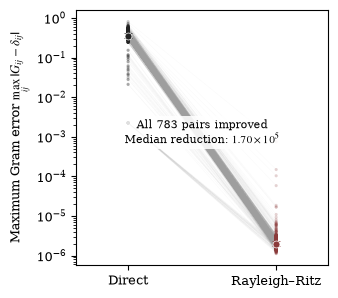

ORTHOGONALITY REAL-DATA AUDIT: PASS
{'configuration': 'FULL', 'split': 'ID_test', 'hamiltonians': 783, 'all_pairs_improved': True, 'median_reduction_factor': 170161.11673144618, 'new_training': False, 'new_inference': False}


In [ ]:
# Stored real-data comparison only: no model loading, inference, or training.
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RUN_DIR=PROJECT/"outputs"/RUN_NAME
FIGURE_DIR=PROJECT/"results"/RUN_NAME/"02_figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
orth_rows=pd.read_csv(RUN_DIR/"orthonormalization_comparison.csv")
orth_rows=orth_rows[orth_rows.category.eq("ID_test")].copy()

# Gram errors are identical across the state rows of a Hamiltonian.
per_group_unique=orth_rows.groupby("group_id")[["gram_pre_max_error","gram_post_max_error"]].nunique()
assert per_group_unique.eq(1).all().all()
assert orth_rows.groupby("group_id").state.nunique().eq(11).all()
orth_pairs=(orth_rows[["group_id","family","gram_pre_max_error","gram_post_max_error"]]
            .drop_duplicates("group_id").sort_values("group_id").reset_index(drop=True))
expected_hamiltonians=len(split_manifest["test"])
assert len(orth_pairs)==orth_rows.group_id.nunique()==expected_hamiltonians
assert (orth_pairs[["gram_pre_max_error","gram_post_max_error"]]>0).all().all()
orth_pairs["reduction_factor"]=orth_pairs.gram_pre_max_error/orth_pairs.gram_post_max_error
orth_pairs.to_csv(FIGURE_DIR/"figure_orthogonality_direct_vs_ritz.csv",index=False)

pre=orth_pairs.gram_pre_max_error.to_numpy()
post=orth_pairs.gram_post_max_error.to_numpy()
improved=post<pre
median_reduction=float(np.median(pre/post))
reduction_exponent=int(np.floor(np.log10(median_reduction)))
reduction_mantissa=median_reduction/10**reduction_exponent

plt.rcParams.update({"font.family":"serif",
    "font.serif":["Times New Roman","Times","Nimbus Roman","DejaVu Serif"],
    "mathtext.fontset":"stix","font.size":9,"axes.linewidth":0.8,
    "xtick.major.width":0.8,"ytick.major.width":0.8})
direct_color="#222222"; ritz_color="#8b3a3a"
fig,ax=plt.subplots(figsize=(3.45,3.05))
for before,after in zip(pre,post):
    ax.plot([0,1],[before,after],color="0.62",lw=0.35,alpha=0.055,zorder=1,rasterized=True)
ax.scatter(np.zeros_like(pre),pre,s=5,color=direct_color,alpha=0.22,edgecolors="none",zorder=2,rasterized=True)
ax.scatter(np.ones_like(post),post,s=5,color=ritz_color,alpha=0.22,edgecolors="none",zorder=2,rasterized=True)
for xpos,values,color in ((0,pre,direct_color),(1,post,ritz_color)):
    q25,median,q75=np.quantile(values,[.25,.5,.75])
    ax.errorbar(xpos,median,yerr=[[median-q25],[q75-median]],fmt="o",ms=5.0,
                color=color,mec="white",mew=0.5,lw=1.25,capsize=3,zorder=4)
ax.set_yscale("log")
ax.set_xticks([0,1],labels=["Direct","Rayleigh\u2013Ritz"])
ax.set_ylabel(r"Maximum Gram error $\max_{ij}|G_{ij}-\delta_{ij}|$")
ax.set_xlim(-.35,1.35); ax.grid(False)
ax.text(.50,.52,f"All {len(orth_pairs)} pairs improved"+"\n"
        +rf"Median reduction: ${reduction_mantissa:.2f}\times10^{{{reduction_exponent}}}$",
        transform=ax.transAxes,ha="center",va="center",fontsize=8,
        bbox={"facecolor":"white","edgecolor":"none","alpha":0.86,"pad":1.5})
fig.tight_layout()
fig.savefig(FIGURE_DIR/"figure_orthogonality_direct_vs_ritz.png",dpi=300,bbox_inches="tight")
fig.savefig(FIGURE_DIR/"figure_orthogonality_direct_vs_ritz.pdf",bbox_inches="tight")
plt.show()
assert improved.all() and config["mode"]=="STANDARD"
print("ORTHOGONALITY REAL-DATA AUDIT: PASS")
print({"configuration":"STANDARD","split":"ID_test","hamiltonians":len(orth_pairs),
       "all_pairs_improved":bool(improved.all()),"median_reduction_factor":median_reduction,
       "new_training":False,"new_inference":False})
